**Linear SVM + T3: PCA(20) ---> Polynomial degree 2**

This notebook trains **SVM with transformation T3** for 6 values of `C` (6 of our 72 models). It uses the shared splits (`data/processed/`), preprocessing (`src/preprocessing.py`) and evaluation (`src/evaluation.py`), so the results can be merged with the other notebooks. We only use train and validation here; the test set is used once at the end of the project.

**Linear SVM** (`LinearSVC`) also draws a straight boundary $w^\top x + b = 0$, but instead of probabilities it looks for the boundary with the widest **margin** (the biggest gap between the boundary and the closest flows of each class). Flows on the wrong side or inside the margin are penalized with the (squared) hinge loss.

**Regularization:** sklearn minimizes

$$\frac{1}{2}\lVert w \rVert^2 + C \sum_{i} \max(0,\, 1 - y_i\, w^\top x_i)^2$$

Same idea as logistic regression: **small `C` ---> strong regularization** (wide margin, tolerates more mistakes), **large `C` ---> weak regularization** (tries hard to classify every training flow correctly, risk of overfitting).

**1. Setup**

In [1]:
import sys
sys.path.append("..") # so we can import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import LinearSVC

from src.preprocessing import RANDOM_STATE, build_preprocessor, load_split
from src.evaluation import evaluate, plot_sweep, attack_recall, RESULTS

FIGS = RESULTS.parent / "figures"
RESULTS.mkdir(exist_ok=True)

X_train, y_train, cat_train = load_split("train")
X_val, y_val, cat_val = load_split("val")
print("train:", X_train.shape, " val:", X_val.shape)

train: (24000, 41)  val: (6000, 41)


**2. The transformation: PCA(20) ---> polynomial degree 2**

Polynomial degree 2 adds all squares and pairwise products, which lets the linear SVM draw curved boundaries (ellipses, parabolas) and capture "both features high at once" interactions. On all 73 features this would give 2,774 columns; compressing to 20 components first keeps it at

$$\binom{20 + 2}{2} - 1 = 230 \text{ columns}$$

We add a `StandardScaler` after the polynomial step so the squared terms are on the same scale as the rest.

**Why do we do this?**: Compress first, then add pairwise interactions ---> curved boundaries at a small fraction of the full polynomial size

In [2]:
prep = build_preprocessor().fit(X_train)
Xt_train = prep.transform(X_train)
pca20 = PCA(n_components=20, random_state=RANDOM_STATE).fit(Xt_train)
poly = PolynomialFeatures(degree=2, include_bias=False).fit(pca20.transform(Xt_train))

print(f"PCA(20) keeps {pca20.explained_variance_ratio_.sum():.1%} of the variance")
print("columns: 73 ---> 20 ---> ", poly.n_output_features_)
print("(full polynomial degree 2 on 73 features would be", PolynomialFeatures(degree=2, include_bias=False).fit(Xt_train[:5]).n_output_features_, "columns)")

PCA(20) keeps 96.7% of the variance
columns: 73 ---> 20 --->  230
(full polynomial degree 2 on 73 features would be 2774 columns)


PCA(20) keeps **96.7% of the variance**, which is more than the other PCA-based models (95% with 17 components in LR T2, and 93.5% with 15 in LR T3), so this transformation throws away the least information of the three. The polynomial step then turns the 20 components into 230 columns: the 20 originals, their 20 squares, and 190 pairwise products.

That's about 12 times smaller than a full degree-2 expansion on all 73 features (2,774 columns), and also much smaller than LR T3 (815 columns), since we only go up to degree 2 here. So this model can draw curved boundaries (like ellipses) and use "both components high at once" interactions, but with a lot fewer columns to fit.

**3. The pipeline**

The full pipeline: shared preprocessing (73 features) ---> PCA(20) ---> polynomial degree 2 (230 columns) ---> scaling ---> linear SVM.

In [3]:
def build(C):
    return make_pipeline(build_preprocessor(),
                         PCA(n_components=20, random_state=RANDOM_STATE),
                         PolynomialFeatures(degree=2, include_bias=False),
                         StandardScaler(),
                         LinearSVC(C=C, dual="auto", max_iter=5000, random_state=RANDOM_STATE))

**4. Regularization sweep**

We train one model for each of the 6 values of `C` (smaller `C` = stronger regularization). Every model is fit on the 24,000 training rows and scored on both train and validation. `f1_gap` = train F1 - validation F1: a big gap means overfitting, while low F1 on both means underfitting.

In [4]:
GRID = [1e-3, 1e-2, 1e-1, 1, 10, 100]
rows, fitted = [], {} # fitted keeps each trained pipeline, so we don't have to retrain the best one

for value in GRID:
    pipe = build(value)
    rows.append(evaluate(pipe, "SVM", "T3", "C", value, X_train, y_train, X_val, y_val))
    fitted[value] = pipe
    print(f"C={value:g}: val F1 = {rows[-1]['val_f1']:.4f}, fit time = {rows[-1]['fit_time_s']}s")

results = pd.DataFrame(rows)
results["f1_gap"] = results["train_f1"] - results["val_f1"]
results.drop(columns=["model", "transformation", "param"]).round(4)

C=0.001: val F1 = 0.9149, fit time = 0.82s
C=0.01: val F1 = 0.9152, fit time = 1.22s
C=0.1: val F1 = 0.9142, fit time = 2.03s
C=1: val F1 = 0.9175, fit time = 2.78s
C=10: val F1 = 0.9171, fit time = 11.56s
C=100: val F1 = 0.9171, fit time = 11.59s


,value,train_precision,train_recall,train_f1,train_fpr,val_precision,val_recall,val_f1,val_fpr,fit_time_s,converged,f1_gap
0,0.001,0.8725,0.9666,0.9171,0.1520,0.8718,0.9624,0.9149,0.1522,0.82,True,0.0023
1,0.010,0.8811,0.9616,0.9196,0.1396,0.8773,0.9566,0.9152,0.1439,1.22,True,0.0044
2,0.100,0.8910,0.9559,0.9223,0.1259,0.8836,0.9469,0.9142,0.1343,2.03,True,0.0081
3,1.000,0.8947,0.9519,0.9224,0.1206,0.8909,0.9457,0.9175,0.1246,2.78,True,0.0049
4,10.000,0.8960,0.9512,0.9228,0.1189,0.8926,0.9431,0.9171,0.1221,11.56,True,0.0056
5,100.000,0.8962,0.9511,0.9228,0.1186,0.8926,0.9431,0.9171,0.1221,11.59,True,0.0057


**5. Validation curve**

Left: train F1 (dashed) vs validation F1 (solid). Right: validation precision, recall and false positive rate, to see what the regularization trades off.

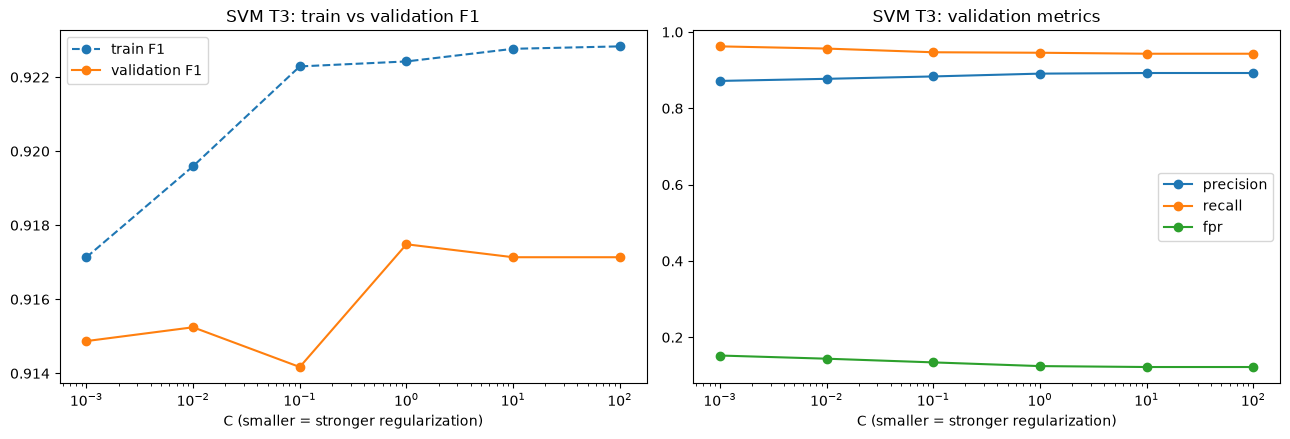

In [5]:
plot_sweep(results, "SVM T3", FIGS / "curve_svm_t3_pca_poly2.png")

Weaker regularization (larger `C`) makes the SVM work harder to get every training flow right, so the fit time grows. We check how much.

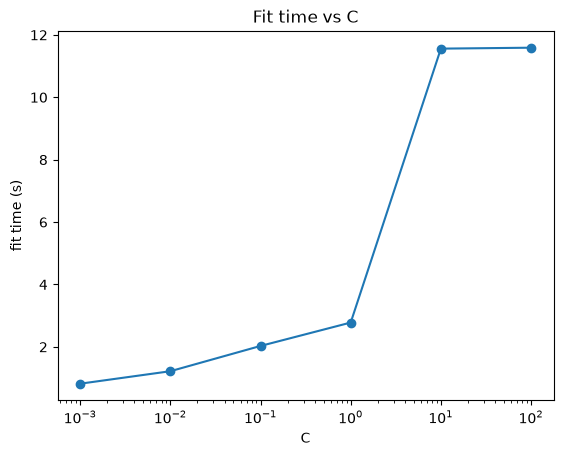

In [6]:
plt.plot(results["value"], results["fit_time_s"], "-o")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("fit time (s)")
plt.title("Fit time vs C")
plt.show()

Validation F1 doesn't change much with `C`: it stays between 0.9142 and 0.9175. The best is `C` = 1 (0.9175), and the small dip at `C` = 0.1 (0.9142) is most likely just noise, since the values around it are higher. The best `C` is not at the edge of the grid, so no need to extend it.

Something we noticed is that `C` = 10 and `C` = 100 give exactly the same validation results. Past `C` = 10 the regularization stops having any effect, and the SVM just settles on the same boundary. But it takes about 4 times longer to get there (11.6s vs 2.8s at `C` = 1), so weaker regularization here only costs time.

There's no real overfitting either. Training F1 goes up from 0.917 to 0.923 and then flattens, and the gap with validation is at most 0.008. So, like SVM T2, this model seems limited by how much it can express with 230 quadratic features, not by the regularization.

`C` again trades recall for fewer false alarms: from `C` = 0.001 to 100, precision goes up from 0.872 to 0.893 and FPR drops from 0.152 to 0.122, while recall drops from 0.962 to 0.943.

Its best F1 (0.9175) is basically tied with SVM T2 (0.9170) and LR T3 (0.9179), so on F1 alone the curved boundary from the polynomial terms doesn't beat the K-means distances.

**6. The best setting**

We pick the `C` with the highest validation F1. If it is at the edge of the grid, the best value might be outside it, and we should consider extending the grid.

In [7]:
best = results.loc[results["val_f1"].idxmax()]
best_model = fitted[best["value"]]
print(f"best C = {best['value']:g}: val F1 = {best['val_f1']:.4f}, precision = {best['val_precision']:.4f}, "
      f"recall = {best['val_recall']:.4f}, FPR = {best['val_fpr']:.4f}")
if best["value"] in (GRID[0], GRID[-1]):
    print("the best value is at the edge of the grid ---> consider extending it")

best C = 1: val F1 = 0.9175, precision = 0.8909, recall = 0.9457, FPR = 0.1246


The confusion matrix on the validation set: the top-right cell is false alarms (normal flagged as attack), the bottom-left cell is missed attacks.

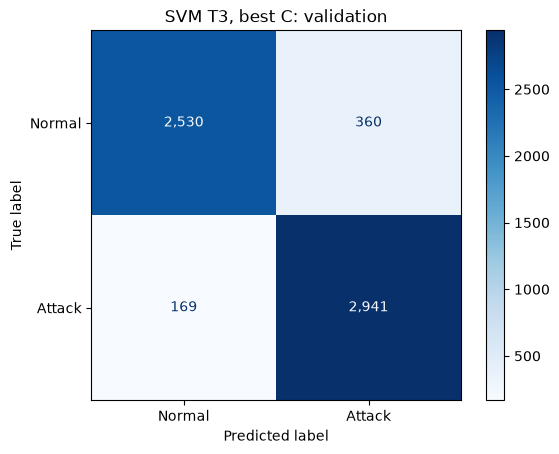

In [8]:
pred_val = best_model.predict(X_val)
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, display_labels=["Normal", "Attack"], cmap="Blues", values_format=",")
plt.title("SVM T3, best C: validation")
plt.savefig(FIGS / "confusion_svm_t3_pca_poly2.png", dpi=150, bbox_inches="tight")
plt.show()

Which attack types does the best model miss? (On validation only, the test set stays untouched.)

In [9]:
attack_recall(y_val, pred_val, cat_val)

,rows,caught,missed,recall
type,,,,
Fuzzers,899,747,152,0.831
Analysis,89,85,4,0.955
DoS,212,210,2,0.991
Exploits,1105,1097,8,0.993
Reconnaissance,419,417,2,0.995
Generic,233,232,1,0.996
Backdoor,85,85,0,1.000
Shellcode,61,61,0,1.000
Worms,7,7,0,1.000


The best model (`C` = 1) makes 360 false alarms (12.5% of normal flows) and misses 169 attacks (5.4%). Compared with SVM T2, it raises fewer false alarms (360 vs 393) but misses more attacks (169 vs 144). So the two SVMs have almost the same F1, but they make different kinds of mistakes.

Almost all of that difference is Fuzzers. This model misses 152 of them (recall 83.1%), which is 90% of everything it misses. On every other type it actually does better than SVM T2: only 17 non-Fuzzers attacks are missed (vs 24), and Exploits are caught 99.3% of the time, the best of any model so far.

Now that all our T2/T3 models are done, there's a pattern in the Fuzzers numbers. The three models that go through PCA miss the most Fuzzers (LR T2: 141, LR T3: 154, SVM T3: 152), while the models that see all 73 features miss fewer (SVM T2: 120, LR T0: 129, MLP wide: 134). The deep MLP (152) doesn't fit this pattern since it has no PCA, so we can't say it's the whole story. But it does suggest that some of the Fuzzers signal is in the low-variance directions that PCA throws away, which is exactly the risk we mentioned when we introduced PCA.

**7. Save the results**

We save the 6 rows to `results/svm_t3_pca_poly2.csv`, so they can be merged with the other notebooks into the 72-row results table.

In [10]:
results.to_csv(RESULTS / "svm_t3_pca_poly2.csv", index=False)
print("saved", len(results), "rows to", RESULTS / "svm_t3_pca_poly2.csv")

saved 6 rows to /Users/nerominh/Documents/Fall 2026/Machine Learning/Network Fraud Detection/results/svm_t3_pca_poly2.csv
